# Step 2: kinematics

For every trial: the arm that did the task, measured from the shoulder in the person's own directions, on a regular time grid, filtered, with 2 joint angles and their speeds.

Input: `trials.parquet` and `frames.parquet` from `01_preprocess.ipynb`. Code: `movement.py`.
No trial is selected or removed here (passes_checks, repetition 1, ...): later steps do that.

In [1]:
%load_ext autoreload
%autoreload 2
import matplotlib.pyplot as plt
import pandas as pd

import movement
from config import MAX_FACING_DEG

## Settings
Change a value, then re-run from here. They are saved next to the output (`kinematics_settings.json`).

In [2]:
BODY_FRAME_FROM = "start"   # "start" = turn the trial using the shoulder line of the start posture,
                            # "median" = using the median over the whole trial (old behaviour)
START_FRAMES = 5            # number of frames at the start that define the start posture
FILTER_CUTOFF_HZ = 5        # low-pass filter frequency (Hz); None = no filter
KEEP_UNFILTERED = True      # also keep unfiltered positions (columns prefixed raw_), for wobble/tremor later
MIN_CONFIDENCE = None       # None = keep every point; a number = points with lower _conf become missing
MAX_GAP_FRAMES = 3          # missing stretches up to this many frames are filled by interpolation
MIRROR_LEFT = True          # mirror the left arm so both arms are comparable

In [3]:
# The settings collected for the functions (MAX_FACING_DEG comes from config.py).
settings = {
    "body_frame_from": BODY_FRAME_FROM, "start_frames": START_FRAMES, "filter_cutoff_hz": FILTER_CUTOFF_HZ,
    "keep_unfiltered": KEEP_UNFILTERED, "min_confidence": MIN_CONFIDENCE, "max_gap_frames": MAX_GAP_FRAMES,
    "mirror_left": MIRROR_LEFT, "max_facing_deg": MAX_FACING_DEG,
}
trials, frames = movement.load_inputs()
print(f"{len(trials)} trials, {len(frames):,} frames")

2803 trials, 429,731 frames


## Build the kinematics

What happens to each trial:
1. **Frames used:** only the movement (`time_s` ≥ 0), and only the arm that did the task (`side`) + both shoulders. Frames of another person (`is_main_person` False), or points below `MIN_CONFIDENCE`, count as missing.
2. **Regular time grid** at the camera's median frame rate in the trial (12 to 38 frames per second depending on the session), by interpolation. Speeds and filters need evenly spaced times. Gaps longer than `MAX_GAP_FRAMES` frames are not bridged: they stay missing.
3. **Filter:** low-pass Butterworth at `FILTER_CUTOFF_HZ`, run forward and backward so peaks are not shifted in time. It removes the camera jitter, which is much faster than an arm movement. Each continuous piece is filtered on its own; pieces shorter than 16 frames are left as they are (`n_frames_unfiltered`).
4. **Body frame:** the shoulder is the origin. Each trial is turned using the line between the 2 shoulders, so that `forward` = in front of the chest, `out` = to the side away from the body, `up` = up. Some people sit turned: without this, the same arm raise would look "forward" for one and "forward + sideways" for another. The left arm is mirrored so `out` is positive for both arms. Body turned by more than `MAX_FACING_DEG` → `facing_ok` = False (flag only).
5. **Angles:** `elbow_angle_deg` (180 = straight arm) and `arm_elevation_deg` (0 = arm hanging, 90 = horizontal, 180 = straight up).
6. **Speeds:** `wrist_speed` (m/s), `elbow_angle_speed` and `arm_elevation_speed` (deg/s, + = the elbow opens / the arm goes up).

Every trial with at least 2 usable frames is computed.

In [4]:
kinematics, kinematics_trials = movement.build_kinematics(frames, trials, settings)

print(f"Trials computed: {len(kinematics_trials)} / {len(trials)} (the others have fewer than 2 usable frames)")
print(f"  body turned by more than {MAX_FACING_DEG} degrees (facing_ok False): {(~kinematics_trials['facing_ok']).sum()}")
print(f"  with a gap longer than {MAX_GAP_FRAMES} frames (has_long_gap):         {kinematics_trials['has_long_gap'].sum()}")
print(f"  with frames left unfiltered (piece too short):              {(kinematics_trials['n_frames_unfiltered'] > 0).sum()}")
print(f"Frames on the grid: {len(kinematics):,}")
kinematics_trials.head()

Trials computed: 2788 / 2803 (the others have fewer than 2 usable frames)
  body turned by more than 45 degrees (facing_ok False): 2
  with a gap longer than 3 frames (has_long_gap):         157
  with frames left unfiltered (piece too short):              65
Frames on the grid: 418,526


,trial_id,side,facing_deg,facing_ok,frame_rate_hz,n_frames,n_missing_filled,has_long_gap,n_frames_unfiltered,upper_arm_length_m,forearm_length_m,arm_length_m
0,upper_limb_20260629_090253_001,right,-3.648727,True,18.773349,36,1,False,0,0.262499,0.241404,0.496535
1,upper_limb_20260629_090253_002,right,0.151559,True,19.021528,26,2,False,0,0.260395,0.236282,0.492818
2,upper_limb_20260629_090253_003,right,1.303248,True,18.928091,25,2,False,0,0.255916,0.239832,0.487620
3,upper_limb_20260629_090253_004,right,2.101785,True,19.363659,28,3,False,0,0.258525,0.234014,0.488521
4,upper_limb_20260629_090253_005,right,2.364731,True,18.522314,25,2,False,0,0.255438,0.232727,0.488984


## The movement table
`kinematics`: one row per frame on the regular grid, saved as `kinematics.parquet`.
Elbow and wrist positions from the shoulder (m, filtered; `raw_` = not filtered), the 2 angles (degrees) and the speeds.

In [5]:
pd.set_option("display.max_columns", None)
print(f"{len(kinematics):,} rows x {kinematics.shape[1]} columns")
kinematics.head(20)

418,526 rows x 19 columns


,trial_id,time_s,elbow_forward,elbow_out,elbow_up,wrist_forward,wrist_out,wrist_up,raw_elbow_forward,raw_elbow_out,raw_elbow_up,raw_wrist_forward,raw_wrist_out,raw_wrist_up,elbow_angle_deg,arm_elevation_deg,wrist_speed,elbow_angle_speed,arm_elevation_speed
0,upper_limb_20260629_090253_001,0.053226,0.011306,0.098128,-0.260646,0.078335,0.122439,-0.489700,0.011303,0.098127,-0.260646,0.078330,0.122439,-0.489700,160.026930,20.755216,0.098140,32.867862,-17.959452
1,upper_limb_20260629_090253_001,0.106493,0.012171,0.093766,-0.262651,0.076620,0.120716,-0.494328,0.013076,0.093678,-0.262271,0.075351,0.121039,-0.496412,161.777703,19.798570,0.075993,8.902878,-12.151173
2,upper_limb_20260629_090253_001,0.159760,0.010711,0.092388,-0.263216,0.077889,0.117123,-0.495789,0.009894,0.092248,-0.263880,0.079047,0.116929,-0.493730,160.975389,19.460703,0.082342,-29.070418,-1.107866
3,upper_limb_20260629_090253_001,0.213027,0.008284,0.093500,-0.262439,0.080999,0.113143,-0.494986,0.008465,0.093797,-0.261821,0.080877,0.112953,-0.495512,158.680715,19.680544,0.073503,-32.554671,4.683458
4,upper_limb_20260629_090253_001,0.266294,0.007602,0.094627,-0.261395,0.083424,0.112094,-0.493466,0.007808,0.094495,-0.261626,0.082900,0.112657,-0.493918,157.507210,19.959650,0.057849,-6.765537,3.787135
5,upper_limb_20260629_090253_001,0.319561,0.009008,0.094853,-0.260591,0.085041,0.114782,-0.490632,0.008651,0.094858,-0.260773,0.085300,0.114078,-0.490557,157.959955,20.084003,0.095327,10.996842,2.729243
6,upper_limb_20260629_090253_001,0.372828,0.011151,0.095131,-0.259624,0.087122,0.118484,-0.486493,0.011602,0.095036,-0.259258,0.087717,0.118606,-0.485590,158.678748,20.250408,0.097688,10.780989,4.895575
7,upper_limb_20260629_090253_001,0.426095,0.013271,0.096102,-0.258025,0.089053,0.121256,-0.483541,0.013042,0.096218,-0.258322,0.088011,0.122062,-0.484839,159.108497,20.605548,0.062905,11.611687,7.478144
8,upper_limb_20260629_090253_001,0.479362,0.015019,0.097304,-0.255858,0.088491,0.124373,-0.483602,0.014702,0.097365,-0.255806,0.088212,0.123995,-0.483630,159.915787,21.047084,0.056679,15.308081,6.803641
9,upper_limb_20260629_090253_001,0.532629,0.016007,0.097779,-0.253730,0.086794,0.126854,-0.483383,0.016501,0.097618,-0.253480,0.089743,0.125328,-0.480501,160.739328,21.330367,0.065101,3.315696,1.071696


## Check: one trial
Wrist height raw vs filtered, wrist speed, and the 2 angles over time. Choose the trial in the next cell (any `trial_id` of `kinematics_trials`).

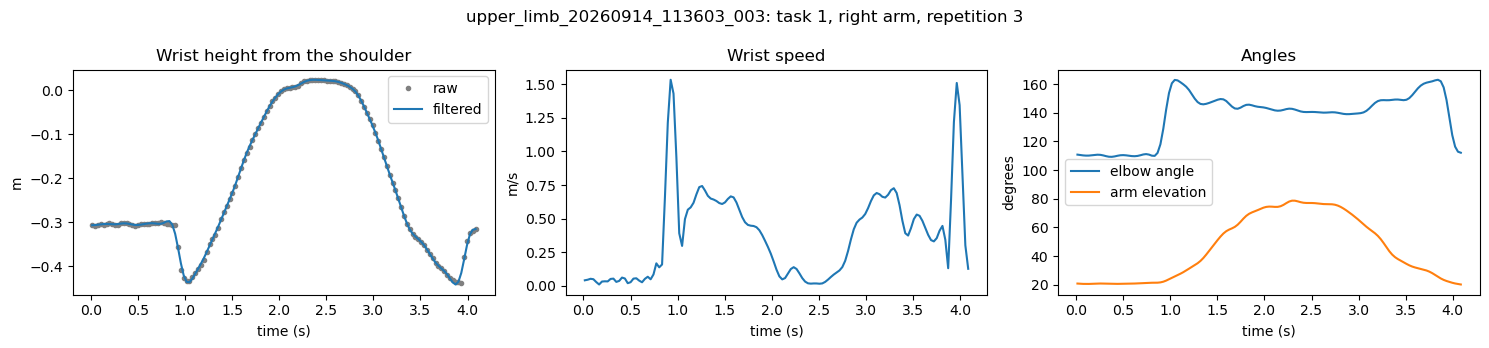

In [7]:
CHECK_TRIAL = "upper_limb_20260914_113603_003"   # task 1 (arm raised forward), repetition 3

one = kinematics[kinematics["trial_id"] == CHECK_TRIAL]
info = trials.set_index("trial_id").loc[CHECK_TRIAL]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))

if KEEP_UNFILTERED:
    axes[0].plot(one["time_s"], one["raw_wrist_up"], ".", color="grey", label="raw")
axes[0].plot(one["time_s"], one["wrist_up"], label="filtered")
axes[0].set(title="Wrist height from the shoulder", xlabel="time (s)", ylabel="m")
axes[0].legend()

axes[1].plot(one["time_s"], one["wrist_speed"])
axes[1].set(title="Wrist speed", xlabel="time (s)", ylabel="m/s")

axes[2].plot(one["time_s"], one["elbow_angle_deg"], label="elbow angle")
axes[2].plot(one["time_s"], one["arm_elevation_deg"], label="arm elevation")
axes[2].set(title="Angles", xlabel="time (s)", ylabel="degrees")
axes[2].legend()

fig.suptitle(f"{CHECK_TRIAL}: task {info['task_id']}, {info['side']} arm, repetition {info['trial_index']}")
plt.tight_layout()

## Check: task 1 (arm raised forward to the target at 90°)
Highest arm elevation of each trial: it should mostly be near or above 90°.

Task 1: 305 trials, median of the highest elevation: 86 degrees, 84% of the trials at 80 degrees or more


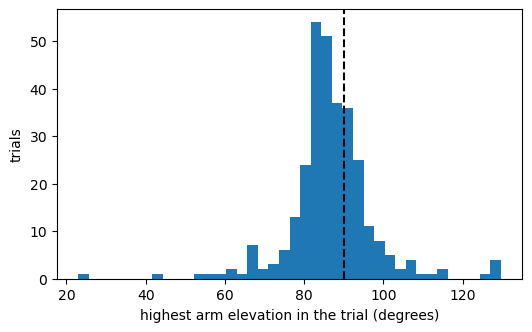

In [8]:
task1_ids = trials.loc[trials["task_id"] == 1, "trial_id"]
max_elevation = kinematics[kinematics["trial_id"].isin(task1_ids)].groupby("trial_id")["arm_elevation_deg"].max()

print(f"Task 1: {len(max_elevation)} trials, median of the highest elevation: {max_elevation.median():.0f} degrees, "
      f"{(max_elevation >= 80).mean():.0%} of the trials at 80 degrees or more")
plt.figure(figsize=(6, 3.5))
plt.hist(max_elevation, bins=40)
plt.axvline(90, color="black", linestyle="--")
plt.xlabel("highest arm elevation in the trial (degrees)")
plt.ylabel("trials");

## Save
Writes `kinematics.parquet` (one row per frame), `kinematics_trials.parquet` (one row per trial) and `kinematics_settings.json` (the settings above) to `data/processed/`. Running it again overwrites them.

In [9]:
movement.save_kinematics(kinematics, kinematics_trials, settings)

kinematics.parquet              63.7 MB
kinematics_trials.parquet        0.2 MB
kinematics_settings.json         0.0 MB
